SALES PERFORMANCE ANALYSIS


PHASE 1 Data understanding

In [2]:
import pandas as pd
import numpy as np


In [3]:
df=pd.read_csv("../data/Sample_ Superstore.csv")

In [4]:
print(df.shape)
df.head()

(9994, 19)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,06-12-2016,6/16/2016,Second Class,DV-13045,Corporate,United States,Los Angeles,California,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Row ID        9994 non-null   int64  
 1   Order ID      9994 non-null   object 
 2   Order Date    9994 non-null   object 
 3   Ship Date     9994 non-null   object 
 4   Ship Mode     9994 non-null   object 
 5   Customer ID   9994 non-null   object 
 6   Segment       9994 non-null   object 
 7   Country       9994 non-null   object 
 8   City          9994 non-null   object 
 9   State         9994 non-null   object 
 10  Region        9994 non-null   object 
 11  Product ID    9994 non-null   object 
 12  Category      9994 non-null   object 
 13  Sub-Category  9994 non-null   object 
 14  Product Name  9994 non-null   object 
 15  Sales         9994 non-null   float64
 16  Quantity      9994 non-null   int64  
 17  Discount      9994 non-null   float64
 18  Profit        9994 non-null 

In [6]:
df.isnull().sum()

Row ID          0
Order ID        0
Order Date      0
Ship Date       0
Ship Mode       0
Customer ID     0
Segment         0
Country         0
City            0
State           0
Region          0
Product ID      0
Category        0
Sub-Category    0
Product Name    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,Row ID,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,229.858001,3.789574,0.156203,28.656896
std,2885.163629,623.245101,2.225110,0.206452,234.260108
min,1.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,22638.480000,14.000000,0.800000,8399.976000


In [9]:
print("Ship Modes:", df["Ship Mode"].unique())
print("Segments:", df["Segment"].unique())
print("Categories:", df["Category"].unique())
print("Regions:", df["Region"].unique())

Ship Modes: ['Second Class' 'Standard Class' 'First Class' 'Same Day']
Segments: ['Consumer' 'Corporate' 'Home Office']
Categories: ['Furniture' 'Office Supplies' 'Technology']
Regions: ['South' 'West' 'Central' 'East']


In [10]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="mixed")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="mixed")
df.info()
df[["Order Date", "Ship Date"]].head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Row ID        9994 non-null   int64         
 1   Order ID      9994 non-null   object        
 2   Order Date    9994 non-null   datetime64[ns]
 3   Ship Date     9994 non-null   datetime64[ns]
 4   Ship Mode     9994 non-null   object        
 5   Customer ID   9994 non-null   object        
 6   Segment       9994 non-null   object        
 7   Country       9994 non-null   object        
 8   City          9994 non-null   object        
 9   State         9994 non-null   object        
 10  Region        9994 non-null   object        
 11  Product ID    9994 non-null   object        
 12  Category      9994 non-null   object        
 13  Sub-Category  9994 non-null   object        
 14  Product Name  9994 non-null   object        
 15  Sales         9994 non-null   float64 

,Order Date,Ship Date
0,2016-11-08,2016-11-11
1,2016-11-08,2016-11-11
2,2016-06-12,2016-06-16
3,2015-10-11,2015-10-18
4,2015-10-11,2015-10-18


PHASE 2 Data Cleaning

In [11]:
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts())
    


Order ID
Order ID
CA-2017-100111    14
CA-2017-157987    12
CA-2016-165330    11
US-2016-108504    11
US-2015-126977    10
                  ..
CA-2014-110422     1
CA-2016-125794     1
CA-2017-163566     1
US-2015-151435     1
CA-2016-130225     1
Name: count, Length: 5009, dtype: int64

Ship Mode
Ship Mode
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543
Name: count, dtype: int64

Customer ID
Customer ID
WB-21850    37
MA-17560    34
JL-15835    34
PP-18955    34
CK-12205    32
            ..
AO-10810     1
LD-16855     1
JR-15700     1
CJ-11875     1
RE-19405     1
Name: count, Length: 793, dtype: int64

Segment
Segment
Consumer       5191
Corporate      3020
Home Office    1783
Name: count, dtype: int64

Country
Country
United States    9994
Name: count, dtype: int64

City
City
New York City    915
Los Angeles      747
Philadelphia     537
San Francisco    510
Seattle          428
                ... 
Abilene            1
Montebello      

In [12]:
print("Negative Sales:", (df["Sales"] < 0).sum())
print("Negative Profit:", (df["Profit"] < 0).sum())
print("Zero Quantity:", (df["Quantity"] == 0).sum())
print("Negative Quantity:", (df["Quantity"] < 0).sum())
print("Invalid Discount:",
      ((df["Discount"] > 0) | (df["Discount"] > 1)).sum())

Negative Sales: 0
Negative Profit: 1871
Zero Quantity: 0
Negative Quantity: 0
Invalid Discount: 5196


In [13]:
print("Minimum Discount:", df["Discount"].min())
print("Maximum Discount:", df["Discount"].max())
print("Unique Discount Values:")
print(sorted(df["Discount"].unique()))

Minimum Discount: 0.0
Maximum Discount: 0.8
Unique Discount Values:
[np.float64(0.0), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.3), np.float64(0.32), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8)]


In [14]:
print(
    "Ship date before order date:",
    (df["Ship Date"] < df["Order Date"]).sum()
)

Ship date before order date: 0


In [15]:
print(
    "Invalid Discount:",
    ((df["Discount"] < 0) | (df["Discount"] > 1)).sum()
)

Invalid Discount: 0


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Row ID        9994 non-null   int64         
 1   Order ID      9994 non-null   object        
 2   Order Date    9994 non-null   datetime64[ns]
 3   Ship Date     9994 non-null   datetime64[ns]
 4   Ship Mode     9994 non-null   object        
 5   Customer ID   9994 non-null   object        
 6   Segment       9994 non-null   object        
 7   Country       9994 non-null   object        
 8   City          9994 non-null   object        
 9   State         9994 non-null   object        
 10  Region        9994 non-null   object        
 11  Product ID    9994 non-null   object        
 12  Category      9994 non-null   object        
 13  Sub-Category  9994 non-null   object        
 14  Product Name  9994 non-null   object        
 15  Sales         9994 non-null   float64 

In [17]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Corporate,United States,Los Angeles,California,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164



PHASE 3 EDA (Exploratory data analysis)
step 1 univariate analysis

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

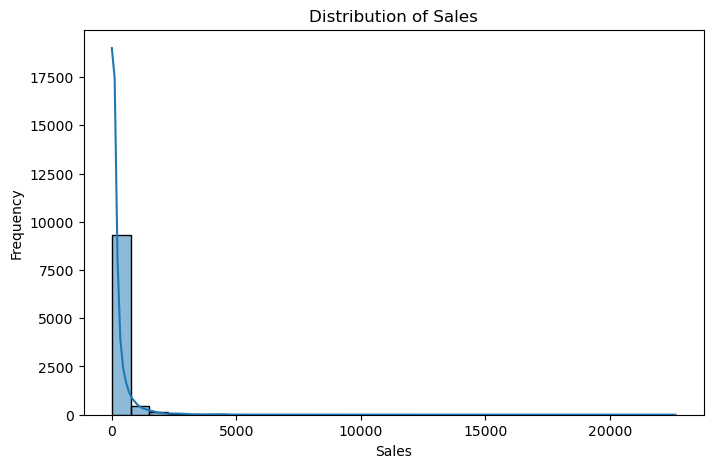

In [19]:
plt.figure(figsize=(8,5))
sns.histplot(df["Sales"], bins=30, kde=True)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

In [20]:
print("Mean Sales:", df["Sales"].mean())
print("Median Sales:", df["Sales"].median())
print("Maximum Sales:", df["Sales"].max())
print("Minimum Sales:", df["Sales"].min())
print("Sales Skewness:", df["Sales"].skew())

Mean Sales: 229.85800083049833
Median Sales: 54.489999999999995
Maximum Sales: 22638.48
Minimum Sales: 0.444
Sales Skewness: 12.97275234181623


### Business Insight – Sales Distribution

- Sales distribution is highly right-skewed.
- Average sales are 229.86, whereas median sales are 54.49.
- The maximum sales value is 22,638.48, indicating the presence of some high-value transactions.
- A relatively small number of high-value transactions pull the average sales upward.

**Conclusion:** Most transactions generate relatively low sales values, while a small number of transactions contribute significantly higher sales.

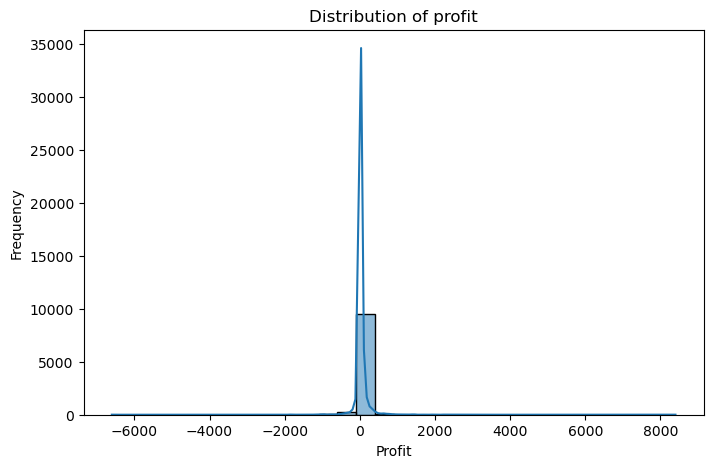

In [21]:
plt.figure(figsize=(8,5))
sns.histplot(df["Profit"], bins=30, kde=True)
plt.title("Distribution of profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

In [22]:
print("Mean Profit:", df["Profit"].mean())
print("Median Profit:", df["Profit"].median())
print("Maximum Profit:", df["Profit"].max())
print("Minimum Profit:", df["Profit"].min())
print("Profit Skewness:", df["Profit"].skew())

print("Loss-making transactions:", (df["Profit"]<0).sum())
print("Profitable transactions:", (df["Profit"]>0).sum())
print("Zero-profit transactions:", (df["Profit"]==0).sum())

Mean Profit: 28.65689630778467
Median Profit: 8.6665
Maximum Profit: 8399.976
Minimum Profit: -6599.978
Profit Skewness: 7.561431562468343
Loss-making transactions: 1871
Profitable transactions: 8058
Zero-profit transactions: 65


### Business Insight – Quantity Distribution

- The average order quantity is approximately 3.79 units.
- The median order quantity is 3 units.
- The most frequently purchased quantity is 3 units, occurring 2,409 times.
- Quantity 2 is also highly frequent, occurring 2,402 times.
- Bulk purchases involving 10–14 units are relatively uncommon.

**Conclusion:** Customers generally purchase smaller quantities, with 2–3 units being the most common order quantities.

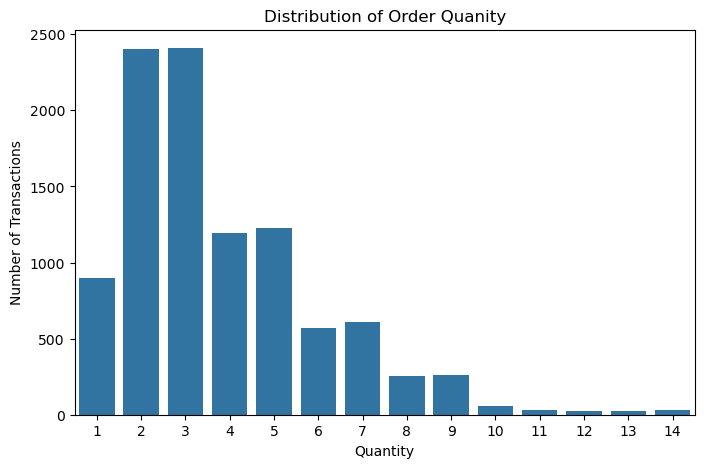

In [23]:
plt.figure(figsize=(8,5))
sns.countplot(x=df["Quantity"])
plt.title("Distribution of Order Quanity")
plt.xlabel("Quantity")
plt.ylabel("Number of Transactions")
plt.show()

In [24]:
print("Average Quantity:", df["Quantity"].mean())
print("Median Quantity:", df["Quantity"].median())
print("Most Frequent Quantity:", df["Quantity"].mode()[0])

print("\nQuantity Frequency:")
print(df["Quantity"].value_counts().sort_index())

Average Quantity: 3.789573744246548
Median Quantity: 3.0
Most Frequent Quantity: 3

Quantity Frequency:
Quantity
1      899
2     2402
3     2409
4     1191
5     1230
6      572
7      606
8      257
9      258
10      57
11      34
12      23
13      27
14      29
Name: count, dtype: int64


### Business Insight – Quantity Distribution

- The average order quantity is approximately 3.79 units.
- The median order quantity is 3 units.
- The most frequently purchased quantity is 3 units, occurring 2,409 times.
- Quantity 2 is also highly frequent, occurring 2,402 times.
- Bulk purchases involving 10–14 units are relatively uncommon.

**Conclusion:** Customers generally purchase smaller quantities, with 2–3 units being the most common order quantities.

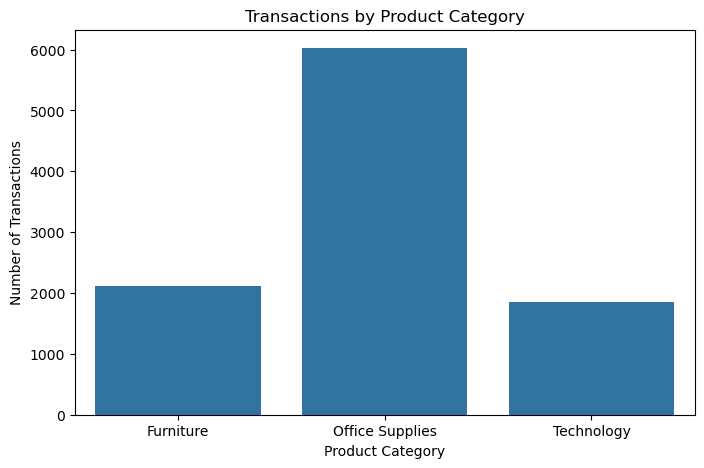

In [25]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Category")
plt.title("Transactions by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")
plt.show()

### Business Insight – Transactions by Product Category

- Office Supplies has the highest number of transactions, with 6,026 records.
- Furniture accounts for 2,121 transactions.
- Technology accounts for 1,847 transactions.
- Office Supplies contributes approximately 60.3% of all transactions.

**Conclusion:** Office Supplies dominates transaction volume. However, higher transaction volume does not necessarily mean higher sales or profitability. Further analysis is needed to compare revenue and profit across categories.

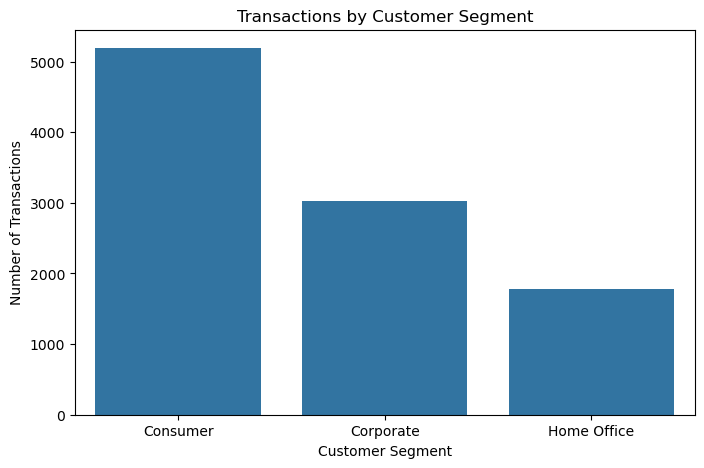

In [26]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Segment")
plt.title("Transactions by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Transactions")
plt.show()

### Business Insight – Transactions by Customer Segment

- Consumer segment has the highest number of transactions, with 5,191 records.
- Corporate segment accounts for 3,020 transactions.
- Home Office segment accounts for 1,783 transactions.
- Consumer customers contribute approximately 52% of total transactions.

**Conclusion:** Consumer customers dominate transaction volume, indicating that individual consumers are the largest customer group in this dataset. Further analysis is required to compare sales and profitability across customer segments.

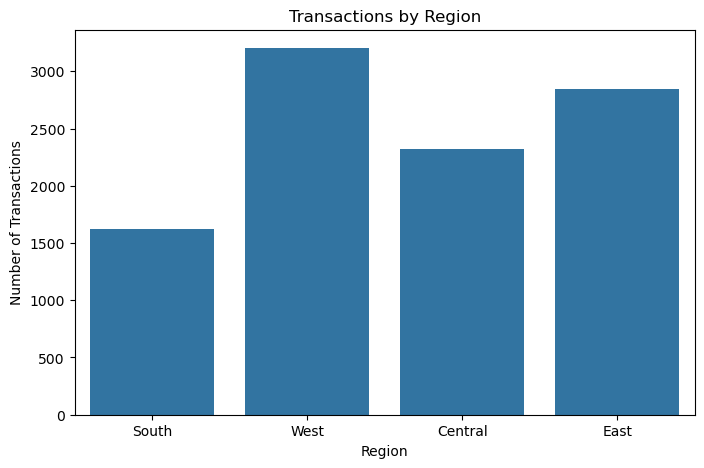

In [27]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Region")
plt.title("Transactions by Region")
plt.xlabel("Region")
plt.ylabel("Number of Transactions")
plt.show()

### Business Insight – Transactions by Region

- West region has the highest transaction volume, with 3,203 records.
- East region accounts for 2,848 transactions.
- Central region accounts for 2,323 transactions.
- South region has the lowest transaction volume, with 1,620 records.
- West contributes approximately 32.05% of total transactions.

**Conclusion:** The West region dominates transaction volume, while the South region has the lowest contribution. Further analysis is required to compare sales and profitability across regions.

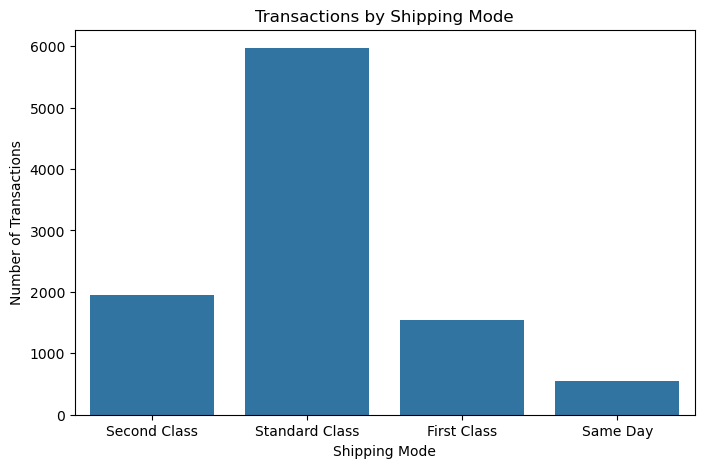

In [28]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Ship Mode")
plt.title("Transactions by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Transactions")
plt.show()

### Business Insight – Transactions by Shipping Mode

- Standard Class has the highest number of transactions, with 5,968 records.
- Second Class accounts for 1,945 transactions.
- First Class accounts for 1,538 transactions.
- Same Day has the lowest usage, with 543 transactions.
- Standard Class contributes approximately 59.72% of total transactions.

**Conclusion:** Standard Class is the most preferred shipping method, while Same Day delivery is used least frequently. This suggests that customers generally choose standard shipping over faster delivery options.

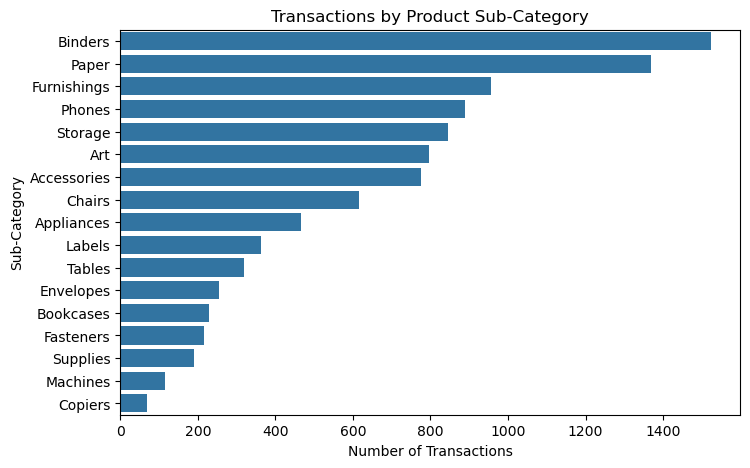

In [29]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    y="Sub-Category",
    order=df["Sub-Category"].value_counts().index
)
plt.title("Transactions by Product Sub-Category")
plt.xlabel("Number of Transactions")
plt.ylabel("Sub-Category")
plt.show()

### Business Insight – Transactions by Product Sub-Category

- Binders have the highest transaction volume, with 1,523 records.
- Paper ranks second, with 1,370 transactions.
- Furnishings ranks third, with 957 transactions.
- Copiers have the lowest transaction volume, with only 68 records.
- Machines also have relatively low transaction volume, with 115 records.

**Conclusion:** Binders and Paper dominate transaction volume, while Copiers and Machines have comparatively fewer transactions. Further analysis is required to determine whether transaction volume translates into higher sales and profitability.

step 2 BIVARIATE ANALYSIS


In [30]:
category_sales = df.groupby("Category")["Sales"].sum()
print(category_sales)

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64


### Business Insight – Category vs Sales

- Technology generates the highest total sales of $836,154.03.
- Furniture generates $741,999.80 in sales.
- Office Supplies generates $719,047.03 in sales.
- Technology generates approximately $117,107 more sales than Office Supplies.

**Conclusion:** Technology is the leading category in terms of total sales, even though Office Supplies has the highest transaction volume. This indicates that transaction volume and revenue contribution are not necessarily the same.

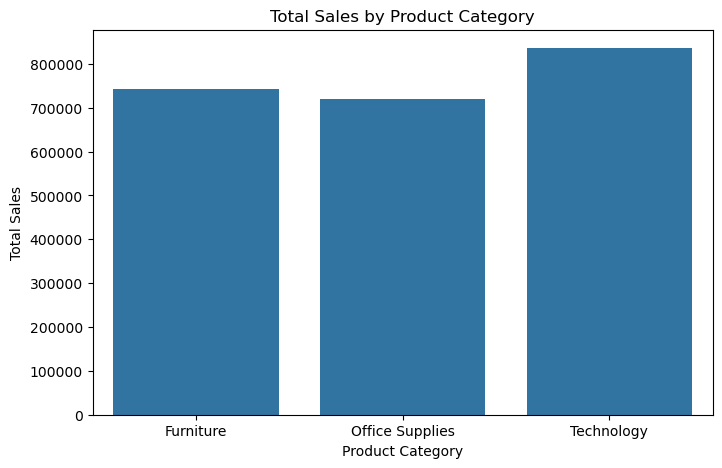

In [31]:
plt.figure(figsize=(8,5))
sns.barplot(x=category_sales.index, y=category_sales.values)
plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.show()

### Business Insight – Category vs Sales

- Technology generates the highest total sales of $836,154.03.
- Furniture generates $741,999.80 in sales.
- Office Supplies generates $719,047.03 in sales.
- Technology generates approximately $117,107 more sales than Office Supplies.

**Conclusion:** Technology is the leading category in terms of revenue, even though Office Supplies has the highest transaction volume. This shows that higher transaction volume does not necessarily mean higher revenue.

In [32]:
category_profit = df.groupby("Category")["Profit"].sum()
print(category_profit)

Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64


### Business Insight – Category vs Profit

- Technology generates the highest total profit of $145,454.95.
- Office Supplies generates $122,490.80 in profit.
- Furniture generates the lowest profit of $18,451.27.
- Despite generating approximately $742K in sales, Furniture contributes relatively low profit.
- Technology generates approximately $127K more profit than Furniture.

**Conclusion:** Technology is the most profitable category, while Furniture has comparatively weak profit contribution despite its substantial sales volume. Further investigation into Furniture discounts and sub-category performance is required.

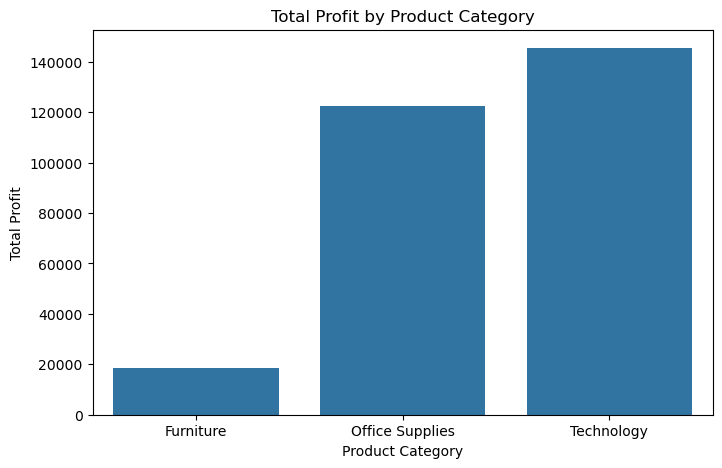

In [33]:
plt.figure(figsize=(8,5))
sns.barplot(x=category_profit.index, y=category_profit.values)
plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.show()

In [34]:
region_sales = df.groupby("Region")["Sales"].sum()
print(region_sales.sort_values(ascending=False))

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


### Business Insight – Region vs Sales

- West region generates the highest sales of $725,457.82.
- East region ranks second with $678,781.24.
- Central region generates $501,239.89.
- South region has the lowest sales of $391,721.91.
- West contributes approximately 31.6% of total sales.

**Conclusion:** The West region is the strongest revenue-generating region, while the South region contributes the least. Further analysis of regional product demand and profitability can help identify opportunities for improvement.

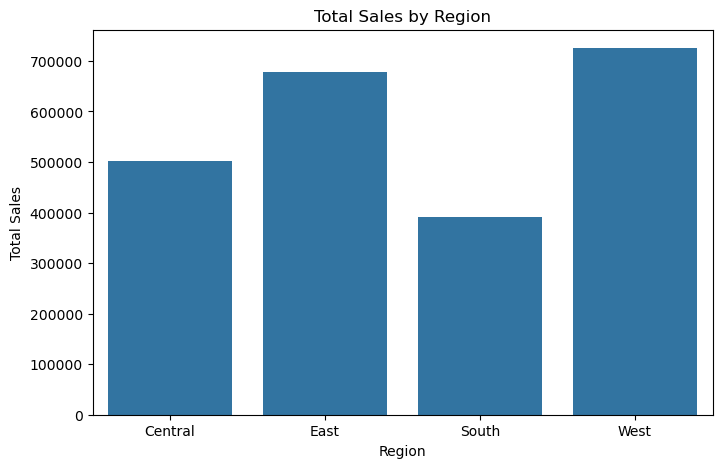

In [35]:
plt.figure(figsize=(8,5))
sns.barplot(x=region_sales.index, y=region_sales.values)
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.show()

* West recorded the highest sales ($725K), followed by East ($679K).
* South had the lowest sales ($392K).
* Sales are concentrated more in the West and East regions.

**Business Insight:** Focus on improving sales performance in the South and Central regions.


In [36]:
region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)
print(region_profit)

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


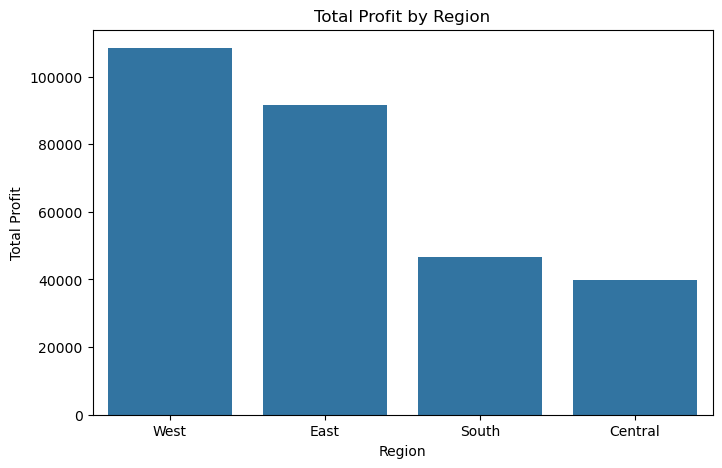

In [37]:
plt.figure(figsize=(8,5))
sns.barplot(x=region_profit.index, y=region_profit.values)
plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.show()

### Business Insight – Profit by Region

- West generates the highest profit ($108.4K), followed by East ($91.5K).
- Central has the lowest profit ($39.7K).

**Conclusion:** West and East are the strongest profit-generating regions, while Central needs improvement.


In [38]:
segment_sales = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)
print(segment_sales)

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64


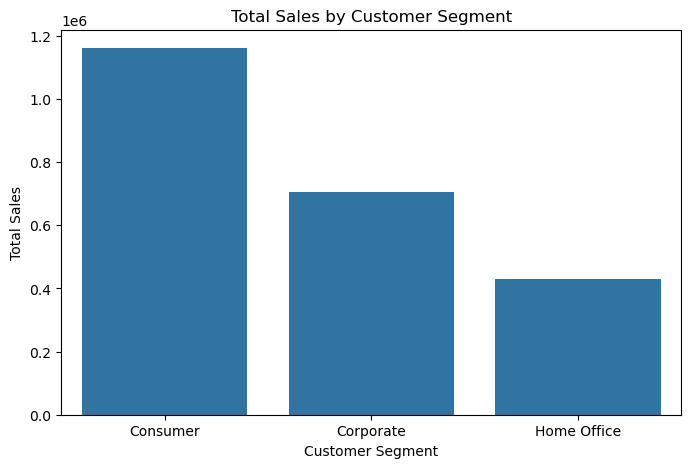

In [39]:
plt.figure(figsize=(8,5))
sns.barplot(x=segment_sales.index, y=segment_sales.values)
plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.show()

### Business Insight – Sales by Segment
- Consumer segment generates the highest sales ($1.16M).
- Corporate contributes approximately $706K.
- Home Office has the lowest sales ($430K).

**Conclusion:** Consumer customers are the largest revenue contributors.

In [40]:
segment_profit= df.groupby("Segment")["Profit"].sum().sort_values(ascending=False)
print(segment_profit)

Segment
Consumer       134119.2092
Corporate       91979.1340
Home Office     60298.6785
Name: Profit, dtype: float64


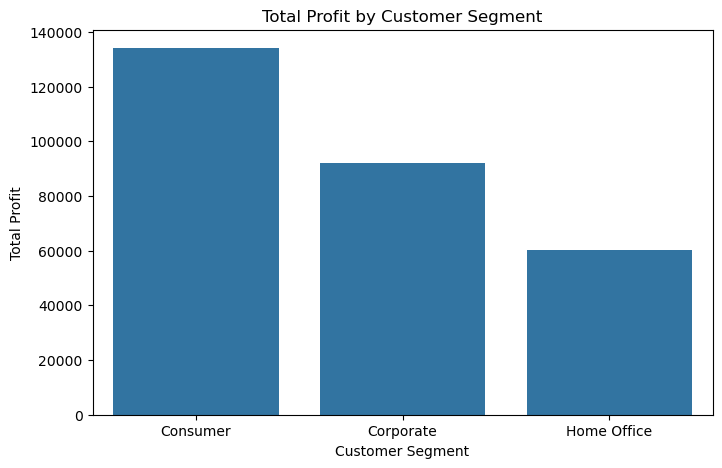

In [41]:
plt.figure(figsize=(8,5))
sns.barplot(x=segment_profit.index, y=segment_profit.values)
plt.title("Total Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit")
plt.show()

### Business Insight – Profit by Segment
- Consumer generates the highest profit ($134.1K).
- Corporate contributes approximately $92K.
- Home Office generates the lowest profit ($60.3K).

**Conclusion:** Consumer is the strongest segment in both sales and profit.

In [42]:
monthly_sales = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()
print(monthly_sales)

Order Date
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


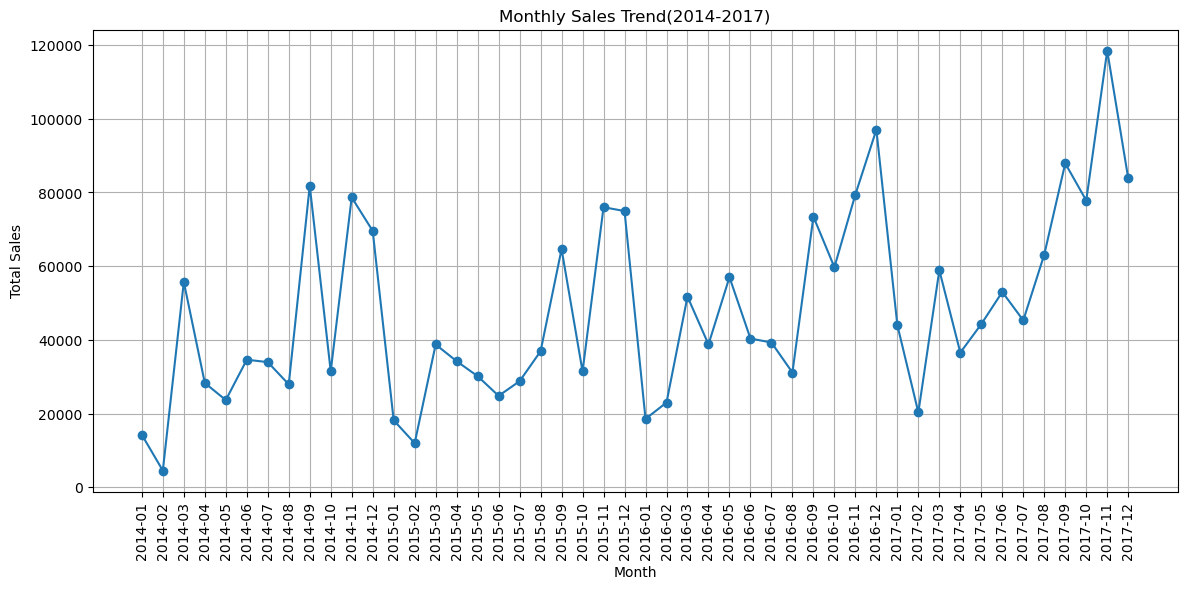

In [43]:
plt.figure(figsize=(14,6))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend(2014-2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

### Business Insight – Monthly Sales Trend
- November 2017 recorded the highest monthly sales ($118.4K).
- February 2014 recorded the lowest monthly sales ($4.5K).
- Sales generally show an upward trend over the four years.

**Conclusion:** Sales performance improved over time, with noticeable monthly fluctuations.

In [44]:
monthly_profit = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Profit"].sum()
print(monthly_profit)

Order Date
2014-01     2450.1907
2014-02      862.3084
2014-03      498.7299
2014-04     3488.8352
2014-05     2738.7096
2014-06     4976.5244
2014-07     -841.4826
2014-08     5318.1050
2014-09     8328.0994
2014-10     3448.2573
2014-11     9292.1269
2014-12     8983.5699
2015-01    -3281.0070
2015-02     2813.8508
2015-03     9732.0978
2015-04     4187.4962
2015-05     4667.8690
2015-06     3335.5572
2015-07     3288.6483
2015-08     5355.8084
2015-09     8209.1627
2015-10     2817.3660
2015-11    12474.7884
2015-12     8016.9659
2016-01     2824.8233
2016-02     5004.5795
2016-03     3611.9680
2016-04     2977.8149
2016-05     8662.1464
2016-06     4750.3781
2016-07     4432.8779
2016-08     2062.0693
2016-09     9328.6576
2016-10    16243.1425
2016-11     4011.4075
2016-12    17885.3093
2017-01     7140.4391
2017-02     1613.8720
2017-03    14751.8915
2017-04      933.2900
2017-05     6342.5828
2017-06     8223.3357
2017-07     6952.6212
2017-08     9040.9557
2017-09    10991.5556

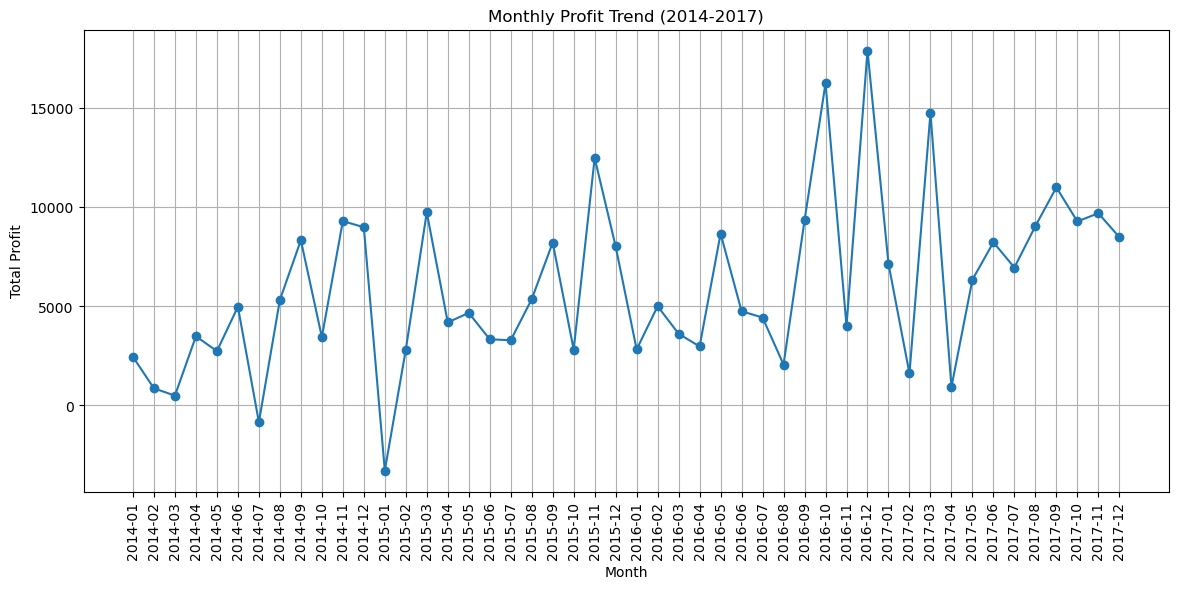

In [45]:
plt.figure(figsize=(14,6))
plt.plot(monthly_profit.index.astype(str), monthly_profit.values, marker="o")
plt.title("Monthly Profit Trend (2014-2017)")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=90)
plt.grid(True)
plt.savefig("monthly_profit_trend.svg", format="svg", bbox_inches="tight")
plt.show()

### Business Insight – Monthly Profit Trend
- December 2016 recorded the highest profit ($17.9K).
- January 2015 recorded the biggest loss (-$3.28K).
- Monthly profit fluctuates considerably across the four years.

**Conclusion:** Higher sales do not always guarantee higher profit.

# Phase 4: Business Insights and Recommendations

This phase summarizes the key findings from exploratory data analysis and identifies opportunities to improve sales performance and profitability.

In [46]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
average_order_value = total_sales/total_orders

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Order Value:", round(average_order_value, 2))

Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793
Average Order Value: 458.61


In [47]:
profit_margin = (total_profit / total_sales)*100
print("Profit Margin :", round(profit_margin, 2), "%")

Profit Margin : 12.47 %


### Insight 1 – Overall Business Performance

- Total sales reached $2.29 million.
- Total profit was $286.40K.
- The business received 5,009 orders from 793 customers.
- Average order value was $458.61.
- Overall profit margin was approximately 12.47%.

**Conclusion:** The business generates positive overall profitability, with opportunities to improve its profit margin.

In [48]:
category_performance = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)
category_performance["Profit_Margin"] = (
    category_performance["Total_Profit"] /
    category_performance["Total_Sales"]
)*100
print(category_performance.round(2))

                 Total_Sales  Total_Profit  Profit_Margin
Category                                                 
Furniture          741999.80      18451.27           2.49
Office Supplies    719047.03     122490.80          17.04
Technology         836154.03     145454.95          17.40


### Insight 2 – Category-wise Performance

- Technology generates the highest sales ($836K) and profit ($145.45K).
- Office Supplies maintains a strong profit margin of 17.04%.
- Furniture has a very low profit margin of 2.49%, despite generating $742K in sales.

**Business Recommendation:** Investigate Furniture discounts, product pricing and sub-category losses to improve profitability.

In [49]:
region_performance = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

region_performance["Profit_Margin"] = (
    region_performance["Total_Profit"] /
    region_performance["Total_Sales"]
) * 100

print(region_performance.round(2))

         Total_Sales  Total_Profit  Profit_Margin
Region                                           
Central    501239.89      39706.36           7.92
East       678781.24      91522.78          13.48
South      391721.90      46749.43          11.93
West       725457.82     108418.45          14.94


### Insight 3 – Regional Business Performance

* West leads in sales ($725.46K) and profit ($108.42K).
* West has the highest profit margin at 14.94%.
* Central has the lowest profit margin at 7.92%, indicating a profitability concern.
* South generates the lowest sales ($391.72K).

**Business Recommendation:** Investigate Central's pricing, discounting and product-level performance to improve profitability.


In [50]:
segment_performance = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

segment_performance["Profit_Margin"] = (
    segment_performance["Total_Profit"] /
    segment_performance["Total_Sales"]
) * 100

print(segment_performance.round(2))

             Total_Sales  Total_Profit  Profit_Margin
Segment                                              
Consumer      1161401.34     134119.21          11.55
Corporate      706146.37      91979.13          13.03
Home Office    429653.15      60298.68          14.03


### Insight 4 – Segment-wise Business Performance

* Consumer generates the highest sales ($1.16M) and profit ($134.12K).
* Home Office has the highest profit margin at 14.03%.
* Corporate maintains a profit margin of 13.03%.
* Consumer has the lowest profit margin at 11.55%.

**Business Recommendation:** Focus on retaining Consumer customers while exploring opportunities to expand the more profitable Home Office segment.


In [51]:
subcategory_performance = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

subcategory_performance["Profit_Margin"] = (
    subcategory_performance["Total_Profit"] /
    subcategory_performance["Total_Sales"]
) * 100

print(subcategory_performance.sort_values(
    by="Total_Profit", ascending=False
).round(2))

              Total_Sales  Total_Profit  Profit_Margin
Sub-Category                                          
Copiers         149528.03      55617.82          37.20
Phones          330007.05      44515.73          13.49
Accessories     167380.32      41936.64          25.05
Paper            78479.21      34053.57          43.39
Binders         203412.73      30221.76          14.86
Chairs          328449.10      26590.17           8.10
Storage         223843.61      21278.83           9.51
Appliances      107532.16      18138.01          16.87
Furnishings      91705.16      13059.14          14.24
Envelopes        16476.40       6964.18          42.27
Art              27118.79       6527.79          24.07
Labels           12486.31       5546.25          44.42
Machines        189238.63       3384.76           1.79
Fasteners         3024.28        949.52          31.40
Supplies         46673.54      -1189.10          -2.55
Bookcases       114880.00      -3472.56          -3.02
Tables    

### Insight 5 – Sub-Category Performance

* Copiers generate the highest total profit ($55.62K).
* Labels have the highest profit margin (44.42%), followed by Paper (43.39%).
* Tables are the biggest loss-making sub-category, with a loss of $17.73K.
* Bookcases and Supplies also generate negative profits.
* Machines have a very low profit margin of 1.79%.

**Business Recommendation:** Review pricing, discounting and costs for Tables, Bookcases and Supplies. Focus on maintaining the strong profitability of Copiers, Labels and Paper.


In [53]:
discount_performance = df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

discount_performance["Profit_Margin"] = (
    discount_performance["Total_Profit"] /
    discount_performance["Total_Sales"]
) * 100

print(discount_performance.round(2))

          Total_Sales  Total_Profit  Total_Orders  Profit_Margin
Discount                                                        
0.00       1087908.47     320987.60          2644          29.51
0.10         54369.35       9029.18            89          16.61
0.15         27558.52       1418.99            51           5.15
0.20        764594.37      90337.31          2407          11.82
0.30        103226.66     -10369.28           211         -10.05
0.32         14493.46      -2391.14            27         -16.50
0.40        116417.78     -23057.05           185         -19.81
0.45          5484.97      -2493.11            10         -45.45
0.50         58918.54     -20506.43            64         -34.80
0.60          6644.70      -5944.66           127         -89.46
0.70         40620.28     -40075.36           344         -98.66
0.80         16963.76     -30539.04           250        -180.03


### Insight 6 – Discount vs Profit Analysis

* Transactions with no discount generate the highest profit ($320.99K) and profit margin (29.51%).
* A 20% discount generates substantial sales ($764.59K) while maintaining positive profitability.
* All discount levels from 30% to 80% show negative overall profits.
* A 70% discount results in the highest total loss of $40.08K.
* An 80% discount has the lowest profit margin (-180.03%).

**Business Recommendation:** Review high-discount policies, particularly discounts of 30% and above, and introduce discount limits based on product profitability.


In [54]:
customer_performance = df.groupby("Customer ID").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

customer_performance = customer_performance.sort_values(
    by="Total_Sales", ascending=False
)

print(customer_performance.head(10).round(2))

             Total_Sales  Total_Profit  Total_Orders
Customer ID                                         
SM-20320        25043.05      -1980.74             5
TC-20980        19052.22       8981.32             5
RB-19360        15117.34       6976.10             6
TA-21385        14595.62       4703.79             4
AB-10105        14473.57       5444.81            10
KL-16645        14175.23        806.86            12
SC-20095        14142.33       5757.41             9
HL-15040        12873.30       5622.43             6
SE-20110        12209.44       2650.68            11
CC-12370        12129.07       2177.05             5


### Insight 7 – Customer Performance

* Customer SM-20320 generates the highest sales ($25.04K) but results in a loss of $1.98K.
* Customer TC-20980 generates $8.98K profit from $19.05K sales.
* Customer KL-16645 has the highest order count (12) among the top 10 customers by sales.
* High customer sales do not always translate into high profitability.

**Business Recommendation:** Monitor customer-level profitability and review pricing and discount strategies for customers generating high sales but low or negative profits.


In [56]:
top_profit_customers = customer_performance.sort_values(
    by="Total_Profit", ascending=False
)

print(top_profit_customers.head(10).round(2))

             Total_Sales  Total_Profit  Total_Orders
Customer ID                                         
TC-20980        19052.22       8981.32             5
RB-19360        15117.34       6976.10             6
SC-20095        14142.33       5757.41             9
HL-15040        12873.30       5622.43             6
AB-10105        14473.57       5444.81            10
TA-21385        14595.62       4703.79             4
CM-12385         8954.02       3899.89             4
KD-16495         8181.26       3038.63            12
AR-10540         6608.45       2884.62             6
DR-12940         8350.87       2869.08             8


### Insight 7 – Customer Performance

* Customer SM-20320 generates the highest sales ($25.04K) but results in a loss of $1.98K.
* Customer TC-20980 generates the highest profit ($8.98K) from $19.05K sales.
* Customer RB-19360 is the second-most profitable customer, generating $6.98K profit.
* Customer KL-16645 has the highest order count (12) among the top 10 customers by sales.
* High customer sales do not always translate into high profitability.

**Business Recommendation:** Monitor customer-level profitability and review pricing and discount strategies for customers generating high sales but low or negative profits.


In [57]:
shipping_performance = df.groupby("Ship Mode").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

shipping_performance["Profit_Margin"] = (
    shipping_performance["Total_Profit"] /
    shipping_performance["Total_Sales"]
) * 100

print(shipping_performance.round(2))

                Total_Sales  Total_Profit  Total_Orders  Profit_Margin
Ship Mode                                                             
First Class       351428.42      48969.84           787          13.93
Same Day          128363.12      15891.76           264          12.38
Second Class      459193.57      57446.64           964          12.51
Standard Class   1358215.74     164088.79          2994          12.08


### Insight 8 – Shipping Performance

* Standard Class generates the highest sales ($1.36M) and profit ($164.09K).
* First Class has the highest profit margin at 13.93%.
* Standard Class handles the highest number of orders (2,994).
* Same Day shipping generates the lowest sales ($128.36K).

**Business Recommendation:** Maintain the efficiency of Standard Class while evaluating opportunities to improve the profitability of other shipping modes.


In [58]:
df["Shipping_Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

shipping_time = df.groupby("Ship Mode")["Shipping_Days"].mean()

print(shipping_time.round(2))

Ship Mode
First Class       2.18
Same Day          0.04
Second Class      3.24
Standard Class    5.01
Name: Shipping_Days, dtype: float64


### Insight 9 – Shipping Time Analysis

* Same Day has the shortest average shipping time (0.04 days).
* First Class takes approximately 2.18 days.
* Second Class takes approximately 3.24 days.
* Standard Class takes approximately 5.01 days.

**Business Recommendation:** Monitor shipping performance across all shipping modes and maintain timely order processing to avoid unnecessary delays.


In [59]:
df["Year"] = df["Order Date"].dt.year

yearly_performance = df.groupby("Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

yearly_performance["Profit_Margin"] = (
    yearly_performance["Total_Profit"] /
    yearly_performance["Total_Sales"]
) * 100

print(yearly_performance.round(2))

      Total_Sales  Total_Profit  Total_Orders  Profit_Margin
Year                                                        
2014    484247.50      49543.97           969          10.23
2015    470532.51      61618.60          1038          13.10
2016    609205.60      81795.17          1315          13.43
2017    733215.26      93439.27          1687          12.74


### Insight 10 – Year-wise Business Performance

* Sales increased from $484.25K in 2014 to $733.22K in 2017.
* Total profit increased consistently, reaching $93.44K in 2017.
* Orders increased from 969 in 2014 to 1,687 in 2017.
* 2016 recorded the highest profit margin of 13.43%.
* 2017 achieved the highest sales and profit, but its profit margin declined to 12.74%.

**Business Recommendation:** Continue focusing on sales growth while monitoring profit margins to ensure that increasing sales translate into sustainable profitability.


In [60]:
yearly_performance["Sales_Growth_%"] = (
    yearly_performance["Total_Sales"].pct_change() * 100
)

yearly_performance["Profit_Growth_%"] = (
    yearly_performance["Total_Profit"].pct_change() * 100
)

print(yearly_performance.round(2))

      Total_Sales  Total_Profit  Total_Orders  Profit_Margin  Sales_Growth_%  \
Year                                                                           
2014    484247.50      49543.97           969          10.23             NaN   
2015    470532.51      61618.60          1038          13.10           -2.83   
2016    609205.60      81795.17          1315          13.43           29.47   
2017    733215.26      93439.27          1687          12.74           20.36   

      Profit_Growth_%  
Year                   
2014              NaN  
2015            24.37  
2016            32.74  
2017            14.24  


### Insight 11 – Year-over-Year Growth Analysis

* Sales declined by 2.83% in 2015, while profit increased by 24.37%.
* In 2016, sales grew by 29.47% and profit by 32.74%.
* In 2017, sales grew by 20.36%, but profit growth slowed to 14.24%.
* The business maintained positive sales and profit growth in both 2016 and 2017.

**Business Recommendation:** Monitor profit growth alongside sales growth to ensure that increasing revenue translates into sustainable profitability.


In [61]:
df.to_csv("../data/Superstore_Cleaned.csv", index=False)

In [62]:
import os

os.path.exists("../data/Superstore_Cleaned.csv")

True

In [63]:
import pandas as pd

check_df = pd.read_csv("../data/Superstore_Cleaned.csv")

print("Original DataFrame:", df.shape)
print("Exported CSV:", check_df.shape)

Original DataFrame: (9994, 21)
Exported CSV: (9994, 21)


In [64]:
print(check_df["Sales"].dtype)

print(check_df["Sales"].head(10))

print(check_df["Sales"].isna().sum())

print(check_df["Sales"].describe())

float64
0    261.9600
1    731.9400
2     14.6200
3    957.5775
4     22.3680
5     48.8600
6      7.2800
7    907.1520
8     18.5040
9    114.9000
Name: Sales, dtype: float64
0
count     9994.000000
mean       229.858001
std        623.245101
min          0.444000
25%         17.280000
50%         54.490000
75%        209.940000
max      22638.480000
Name: Sales, dtype: float64


In [65]:
sales_check = pd.to_numeric(check_df["Sales"], errors="coerce")

print("Invalid Sales values:", sales_check.isna().sum())
print("Data type:", sales_check.dtype)

Invalid Sales values: 0
Data type: float64


In [66]:
import os

print(os.path.abspath("../data/Superstore_Cleaned.csv"))

C:\Users\kashish\OneDrive\Desktop\Sales-performance-analysis\data\Superstore_Cleaned.csv
